In [2]:
import pandas as pd


In [3]:
df = pd.read_csv("../data/train.csv", parse_dates=["Date"], dtype={"StateHoliday": str})

In [4]:
df.shape

(1017209, 9)

In [5]:
df.sample(10)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
496425,1036,7,2014-04-13,0,0,0,0,0,0
763083,94,5,2013-08-16,7080,691,1,1,0,1
357929,1115,7,2014-08-24,0,0,0,0,0,1
885761,122,7,2013-04-28,2117,326,1,0,0,0
746669,405,6,2013-08-31,3192,361,1,0,0,0
824541,227,6,2013-06-22,3777,401,1,0,0,0
90484,170,1,2015-05-11,3554,457,1,0,0,0
145258,309,1,2015-03-23,4915,484,1,0,0,0
191933,154,1,2015-02-09,7039,691,1,0,0,0
445933,719,3,2014-05-28,6726,598,1,0,0,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[us]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  str           
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[us](1), int64(7), str(1)
memory usage: 69.8 MB


In [7]:
df.describe()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,SchoolHoliday
count,1.017209e+06,1.017209e+06,1017209,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,5.584297e+02,3.998341e+00,2014-04-11 01:30:42.846062,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01
min,1.000000e+00,1.000000e+00,2013-01-01 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.800000e+02,2.000000e+00,2013-08-17 00:00:00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00
50%,5.580000e+02,4.000000e+00,2014-04-02 00:00:00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00
75%,8.380000e+02,6.000000e+00,2014-12-12 00:00:00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00
max,1.115000e+03,7.000000e+00,2015-07-31 00:00:00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00
std,3.219087e+02,1.997391e+00,NaN,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01


In [8]:
df["StateHoliday"].nunique()

4

### Sklepy zamknięte a sprzedaż

**Pytanie:** czy kolumna `Open` zgadza się ze sprzedażą?

- Zamknięty (`Open == 0`) i sprzedaż > 0: **0 wierszy**, dane spójne.
- Zamknięty i sprzedaż == 0: **172 817 wierszy** (~17% danych).
- Otwarty (`Open == 1`) i sprzedaż == 0: **54 wiersze**, prawie na pewno błąd danych (awaria kasy, raportowanie).

**Wniosek:** dni zamknięte to reguła biznesowa (zamknięty = 0), a nie coś, czego model ma się uczyć.
Gdyby zostały, ~17% "łatwych zer" sztucznie poprawiłoby metryki.
**Decyzja:** model uczy się tylko na dniach otwartych ze sprzedażą > 0.

In [9]:
len(df[(df["Open"] == 0) & (df["Sales"] > 0)])

0

In [10]:
len(df[(df["Open"] == 1) & (df["Sales"] == 0)])

54

### Filtrowanie: tylko dni otwarte ze sprzedażą

Realizacja decyzji z poprzedniej sekcji. Wynik zapisany jako `df_open`, a oryginalny `df` zostaje nietknięty,
żeby w każdej chwili można było wrócić do pełnych danych.

In [11]:
df_open = df[(df["Open"] == 1) & (df["Sales"] > 0)]

### Rozkład sprzedaży (dni otwarte)

**Pytanie:** jakie wartości dziennej sprzedaży są typowe, a jakie rzadkie?

**Jak czytać:** oś X to wartość sprzedaży podzielona na 50 przedziałów,
oś Y to liczba par sklep-dzień, których sprzedaż wpadła do danego przedziału.

**Wynik:**
- jeden szczyt w okolicy 5–7 tys., czyli typowy dzień typowego sklepu,
- rozkład prawoskośny: długi ogon w stronę wysokich wartości (rzadkie dni do ~41 tys.),
- przy takim kształcie średnia > mediana (ogon ciągnie średnią w górę).

**Wniosek:** histogram miesza dwa źródła rozrzutu, czyli różnice **między sklepami** i różnice **między dniami**.
Zadanie modelu: wyjaśnić, czemu dany sklep danego dnia wypada w ogonie, a nie przy szczycie.
Skośność celu może mieć znaczenie przy wyborze metryki (do sprawdzenia w fazie modelowania).

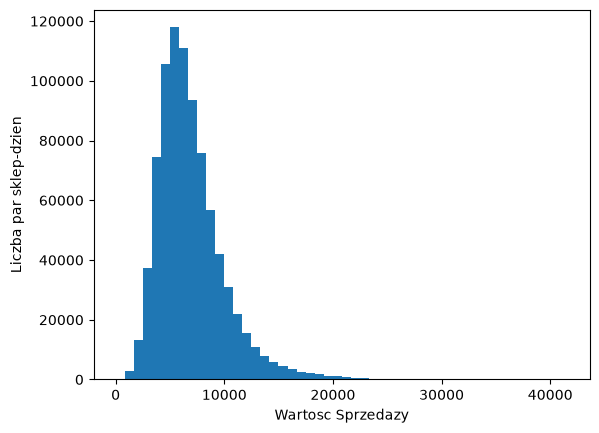

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.hist(df_open["Sales"], bins=50)
ax.set_xlabel("Wartosc Sprzedazy")
ax.set_ylabel("Liczba par sklep-dzien")

plt.show()

### Średnia sprzedaż per dzień tygodnia

**Pytanie:** czy dzień tygodnia przesuwa sprzedaż? (`DayOfWeek`: 1 = poniedziałek, 7 = niedziela)

**Wynik:**
- poniedziałek najwyższy z dni roboczych (~8,2 tys.): możliwe zaległe zakupy po zamkniętej niedzieli,
- wtorek–piątek stabilnie (~6,7–7,1 tys.),
- sobota najniższa (~5,9 tys.), co jest wbrew intuicji,
- niedziela najwyższa (~8,2 tys.), co jest **podejrzane**, bo w Niemczech sklepy w niedziele są w większości zamknięte.

**Wniosek:** dzień tygodnia ma znaczenie, ale wynik niedzieli trzeba zweryfikować, zanim się w niego uwierzy.
Średnia nie mówi, z ilu wierszy ani z jakich sklepów została policzona.

In [13]:
df_open.groupby("DayOfWeek")["Sales"].mean()

DayOfWeek
1    8216.252259
2    7088.409086
3    6728.786679
4    6768.214973
5    7073.034133
6    5875.084935
7    8224.723908
Name: Sales, dtype: float64

### Liczba wierszy per dzień tygodnia

**Pytanie:** czy średnie z poprzedniej komórki są liczone na porównywalnych grupach?

**Wynik:** dni 1–6 mają po ~135–144 tys. wierszy, niedziela tylko **3 593**, czyli ~40× mniej.

**Wniosek:** niedzielna średnia opiera się na ułamku danych. Trzeba sprawdzić, jakie to sklepy.

In [14]:
df_open.groupby("DayOfWeek")["Sales"].count()

DayOfWeek
1    137557
2    143955
3    141922
4    134626
5    138633
6    144052
7      3593
Name: Sales, dtype: int64

### Liczba różnych sklepów per dzień tygodnia

**Pytanie:** czy w niedziele działają te same sklepy co w inne dni?

**Wynik:** dni 1–6 to wszystkie **1115** sklepów, niedziela tylko **33**.

**Wniosek:** wysoka niedzielna średnia nie znaczy "w niedzielę sprzedaje się dużo",
tylko "sklepy otwarte w niedzielę to **inne sklepy**" (najpewniej nietypowe lokalizacje o dużym ruchu).
To efekt składu grupy: porównujemy średnie liczone na różnych zbiorach sklepów.

**Lekcja:** średnia bez liczności grupy może kłamać. `mean()` zawsze w parze z `count()`.
Uczciwe porównanie: te same 33 sklepy, ich niedziele kontra ich pozostałe dni.

In [15]:
df_open.groupby("DayOfWeek")["Store"].nunique()

DayOfWeek
1    1115
2    1115
3    1115
4    1115
5    1115
6    1115
7      33
Name: Store, dtype: int64

### Średnia sprzedaż: promocja kontra brak promocji

**Pytanie:** czy w dni z promocją (`Promo == 1`) sprzedaż jest wyższa?

**Wynik:** bez promocji ~5 930, z promocją ~8 229, czyli **+39%**.

**Uwaga:** to jeszcze NIE znaczy "promocja zwiększa sprzedaż o 39%".
Promocje są planowane, a nie losowe, więc dni z promocją mogą różnić się od pozostałych
także innymi rzeczami (np. dniem tygodnia). Trzeba sprawdzić, kiedy promocje się odbywają.

In [ ]:
df_open.groupby("Promo")["Sales"].mean()

Promo
0    5929.826183
1    8228.739731
Name: Sales, dtype: float64

### Liczność grup promocyjnych

**Pytanie:** czy obie grupy są wystarczająco duże, żeby ich średnie były wiarygodne?

**Wynik:** bez promocji ~467 tys. wierszy, z promocją ~377 tys.

**Wniosek:** obie grupy są duże i porównywalne, więc to nie jest problem jak z niedzielą (33 sklepy).
Pozostaje pytanie, czy grupy różnią się czymś poza samą promocją.

In [19]:
df_open.groupby("Promo")["Sales"].count()

Promo
0    467463
1    376875
Name: Sales, dtype: int64

### Kiedy odbywają się promocje: dzień tygodnia × promocja

**Pytanie:** czy promocje są rozłożone równo na wszystkie dni tygodnia?

**Wynik:**
- w soboty i niedziele promocji **nie ma wcale** (0 wierszy z `Promo == 1`),
- w dni robocze promocja jest w ~52–56% dni, czyli podobnie w każdy dzień.

**Wnioski:**
- grupa "bez promocji" zawiera wszystkie weekendy, a grupa "z promocją" żadnego,
  więc ogólne +39% częściowo miesza efekt promocji z efektem dnia tygodnia
  (dwie cechy splecione ze sobą = **confounding**),
- hipoteza "poniedziałek jest wysoki, bo ma więcej promocji" **odrzucona**: udział promocji
  w poniedziałek jest taki sam jak w inne dni robocze. Wysoki poniedziałek trzeba wyjaśnić
  czymś innym (najpewniej zaległe zakupy po zamkniętej niedzieli).

**Uczciwe porównanie:** dni, które różnią się TYLKO promocją, np. poniedziałek z promocją
kontra poniedziałek bez promocji.

In [20]:
pd.crosstab(df_open["DayOfWeek"], df_open["Promo"])

Promo,0,1
DayOfWeek,,
1,60315,77242
2,66841,77114
3,65671,76251
4,60510,74116
5,66481,72152
6,144052,0
7,3593,0


### Efekt promocji w obrębie każdego dnia tygodnia

**Pytanie:** jaki jest efekt promocji, gdy porównujemy ten sam dzień tygodnia?

**Wynik:**

| Dzień | Bez promocji | Z promocją | Efekt |
|---|---|---|---|
| pon | 6 223 | 9 773 | +57% |
| wt | 5 716 | 8 278 | +45% |
| śr | 5 618 | 7 686 | +37% |
| czw | 5 751 | 7 599 | +32% |
| pt | 6 344 | 7 744 | +22% |

**Wnioski:**
- zniekształcenie przez dzień tygodnia okazało się **małe**: soboty bez promocji sprzedają
  prawie tyle co dni robocze bez promocji, więc nie zaniżyły mocno średniej grupy "bez promocji".
  Mechanizm confoundingu był realny, ale w tych danych słaby. Sprawdzenie było potrzebne.
- **główne odkrycie:** efekt promocji NIE jest stały. Słabnie z każdym dniem tygodnia,
  od +57% w poniedziałek do +22% w piątek. Ogólne +39% to średnia, która ukrywa ten wzór.
- hipotezy (do sprawdzenia): promocje trwają tygodniowymi blokami od poniedziałku
  i najmocniej działają na starcie; w poniedziałek nakładają się promocja i zaległe zakupy.

**Pojęcie: interakcja.** Efekt jednej cechy zależy od wartości drugiej
(promocja działa inaczej w zależności od dnia tygodnia).

**Znaczenie dla modelu (do zrozumienia w fazie 3):**
- regresja liniowa w prostej wersji zakłada, że każda cecha dodaje stałą wartość,
  czyli promocja dodawałaby tyle samo w każdy dzień. Ten wzór sama przeoczy,
  chyba że ręcznie dodamy cechę łączącą promocję z dniem tygodnia.
- las losowy podejmuje decyzje krok po kroku ("jeśli promocja, to sprawdź dzień tygodnia, potem..."),
  więc takie zależności łapie sam.
- to prawdopodobny powód, dla którego las losowy wypadnie lepiej niż regresja.

In [22]:
df_open.groupby(["DayOfWeek", "Promo"])["Sales"].mean()

DayOfWeek  Promo
1          0        6222.727829
           1        9772.910890
2          0        5716.412127
           1        8277.630871
3          0        5617.729043
           1        7685.682535
4          0        5750.882664
           1        7598.788372
5          0        6344.411832
           1        7744.388208
6          0        5875.084935
7          0        8224.723908
Name: Sales, dtype: float64